# California Housing: Linear Regression and Regularization

Compare ordinary least squares, Ridge, Lasso, and Elastic Net regression. Features are standardized using statistics learned from the training set.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [20]:
# Load the California Housing dataset.
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target
feature_names = X.columns.tolist()


In [21]:
# Split the data into 80% training and 20% test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [22]:
# Fit the scaler on training data and transform both splits.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training samples: {len(X_train):,}")
print(f"Test samples: {len(X_test):,}")
print(f"Features: {len(feature_names)}")


Training samples: 16,512
Test samples: 4,128
Features: 8


## Fit models and evaluate test performance

In [23]:
# Define the four requested regression models.
models = {
    "LinearRegression": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0),
    "Lasso (alpha=0.1)": Lasso(alpha=0.1, max_iter=10000),
    "ElasticNet (alpha=0.1)": ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000),
}


In [24]:
# Train each model and save test predictions and coefficients.
predictions = {}
coefficients = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    coefficients[name] = model.coef_


In [25]:
# Compute test-set RMSE, MAE, and R-squared for each model.
metrics = []
for name, y_pred in predictions.items():
    metrics.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R-squared": r2_score(y_test, y_pred),
    })
metrics_df = pd.DataFrame(metrics).set_index("Model")
display(metrics_df.round(4))


,RMSE,MAE,R-squared
Model,,,
LinearRegression,0.7456,0.5332,0.5758
Ridge (alpha=1.0),0.7456,0.5332,0.5758
Lasso (alpha=0.1),0.8244,0.6222,0.4814
ElasticNet (alpha=0.1),0.7974,0.5970,0.5148


### Lasso: features with zero coefficients

Lasso can set some coefficients exactly to zero. The cell below lists the removed features and the features that retain non-zero coefficients.

In [26]:
# Identify features removed by Lasso and features with non-zero coefficients.
lasso_model = models["Lasso (alpha=0.1)"]
lasso_coefficients = pd.Series(lasso_model.coef_, index=feature_names)
zeroed_features = lasso_coefficients[np.isclose(lasso_coefficients, 0.0, atol=1e-8)].index.tolist()
retained_features = lasso_coefficients[~np.isclose(lasso_coefficients, 0.0, atol=1e-8)]

print("Features zeroed by Lasso:")
print(zeroed_features if zeroed_features else "None")
print("\nFeatures with non-zero coefficients:")
display(retained_features.sort_values(key=abs, ascending=False).to_frame("Coefficient"))


Features zeroed by Lasso:
['AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Longitude']

Features with non-zero coefficients:


,Coefficient
MedInc,0.710598
HouseAge,0.106453
Latitude,-0.011469


## Actual vs. predicted values

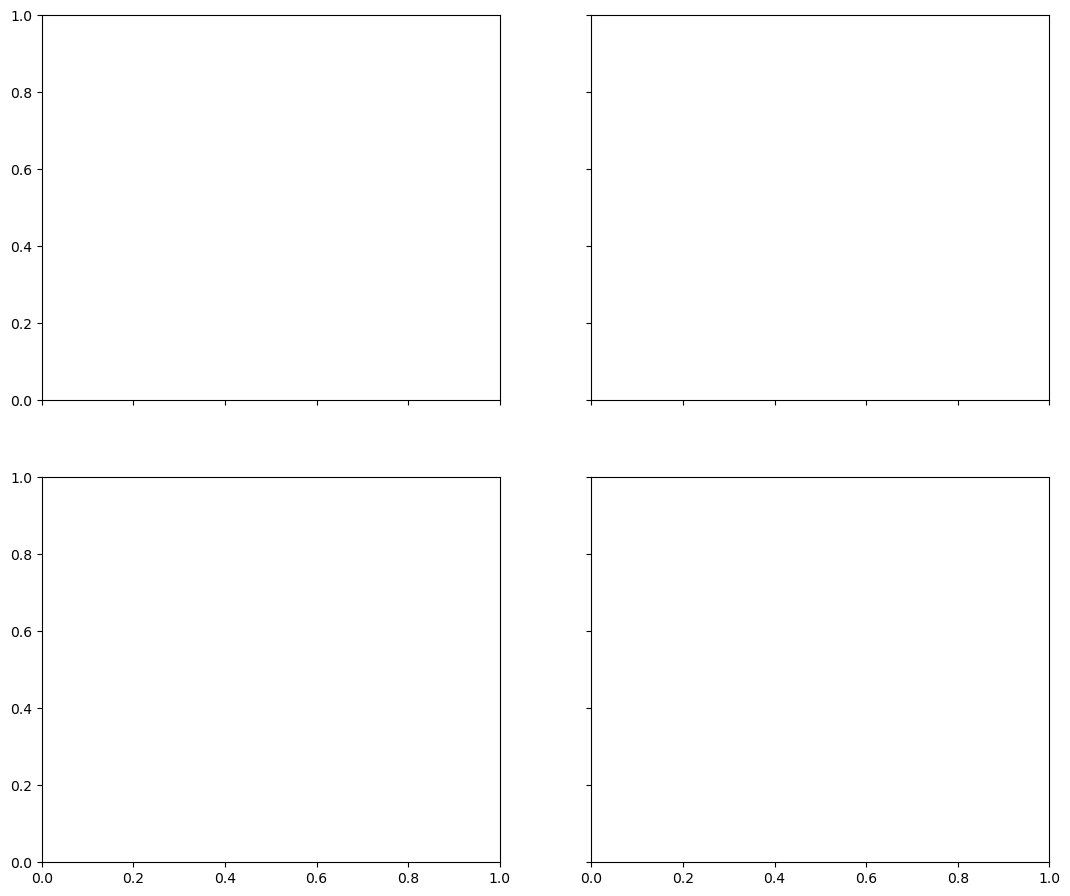

In [27]:
# Create the 2x2 subplot grid and shared comparison limits.
fig, axes = plt.subplots(2, 2, figsize=(13, 11), sharex=True, sharey=True)
axes = axes.ravel()
lower = min(y_test.min(), *(pred.min() for pred in predictions.values()))
upper = max(y_test.max(), *(pred.max() for pred in predictions.values()))


In [28]:
# Draw actual-versus-predicted points for each model.
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.35, s=12)
    ax.plot([lower, upper], [lower, upper], color="red", linestyle="--", linewidth=1.5)
    ax.set_title(name)
    ax.set_xlabel("Actual target")
    ax.set_ylabel("Predicted target")
    ax.grid(alpha=0.2)
fig.suptitle("Actual vs. Predicted California Housing Values", y=1.02)
fig.tight_layout()
plt.show()


## Compare model coefficients

In [29]:
# Arrange the standardized-feature coefficients in a table.
coef_df = pd.DataFrame(coefficients, index=feature_names)


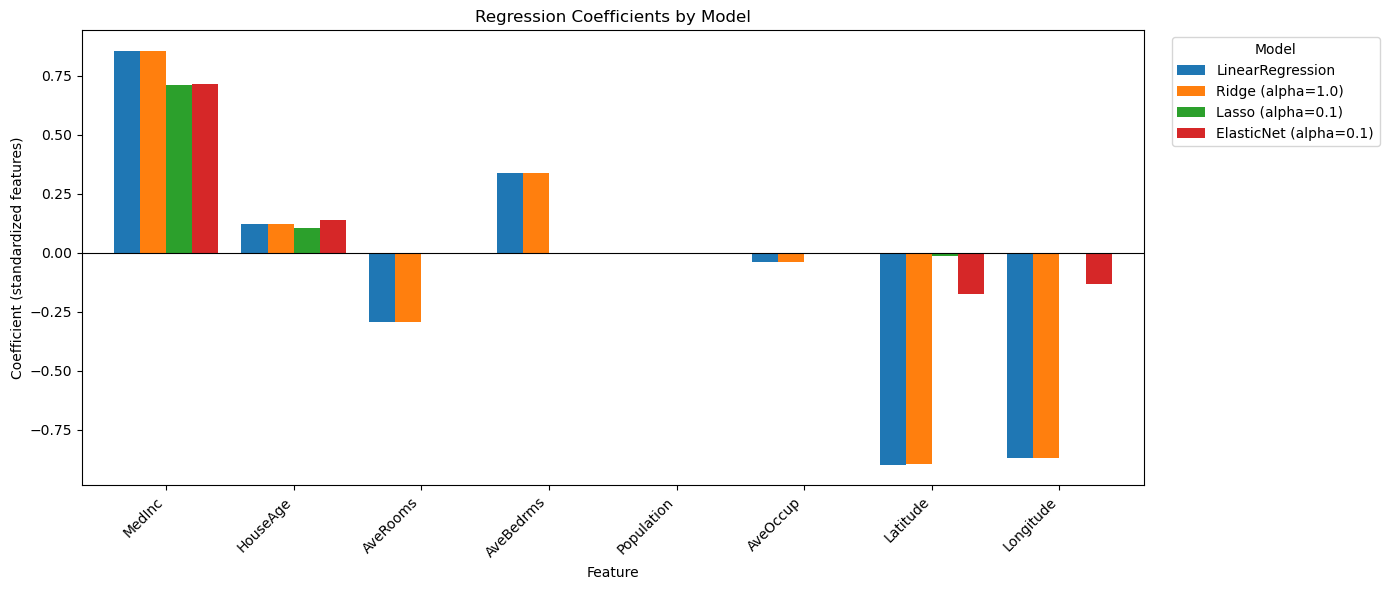

In [30]:
# Plot coefficient values as grouped bars.
ax = coef_df.plot(kind="bar", figsize=(14, 6), width=0.82)
ax.set_title("Regression Coefficients by Model")
ax.set_xlabel("Feature")
ax.set_ylabel("Coefficient (standardized features)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Select alpha with cross-validation

In [31]:
# Define the alpha grid and create the cross-validation estimators.
alphas = np.logspace(-4, 4, 50)
ridge_cv = RidgeCV(alphas=alphas, cv=5)
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=42)


In [32]:
# Fit both cross-validation models and display their selected alpha values.
ridge_cv.fit(X_train_scaled, y_train)
lasso_cv.fit(X_train_scaled, y_train)
print(f"RidgeCV optimal alpha: {ridge_cv.alpha_:.6g}")
print(f"LassoCV optimal alpha: {lasso_cv.alpha_:.6g}")


RidgeCV optimal alpha: 0.0001
LassoCV optimal alpha: 0.000655129


In [33]:
# Evaluate the cross-validated models on the held-out test set.
cv_results = []
for name, model in [("RidgeCV", ridge_cv), ("LassoCV", lasso_cv)]:
    y_pred = model.predict(X_test_scaled)
    cv_results.append({
        "Model": name,
        "Alpha": model.alpha_,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R-squared": r2_score(y_test, y_pred),
    })
display(pd.DataFrame(cv_results).set_index("Model").round(4))


,Alpha,RMSE,MAE,R-squared
Model,,,,
RidgeCV,0.0001,0.7456,0.5332,0.5758
LassoCV,0.0007,0.7450,0.5332,0.5765


## Regularization paths

In [34]:
# Fit Ridge and Lasso at every alpha to calculate their coefficients.
ridge_path = np.vstack([
    Ridge(alpha=alpha).fit(X_train_scaled, y_train).coef_ for alpha in alphas
])
lasso_path = np.vstack([
    Lasso(alpha=alpha, max_iter=10000).fit(X_train_scaled, y_train).coef_ for alpha in alphas
])


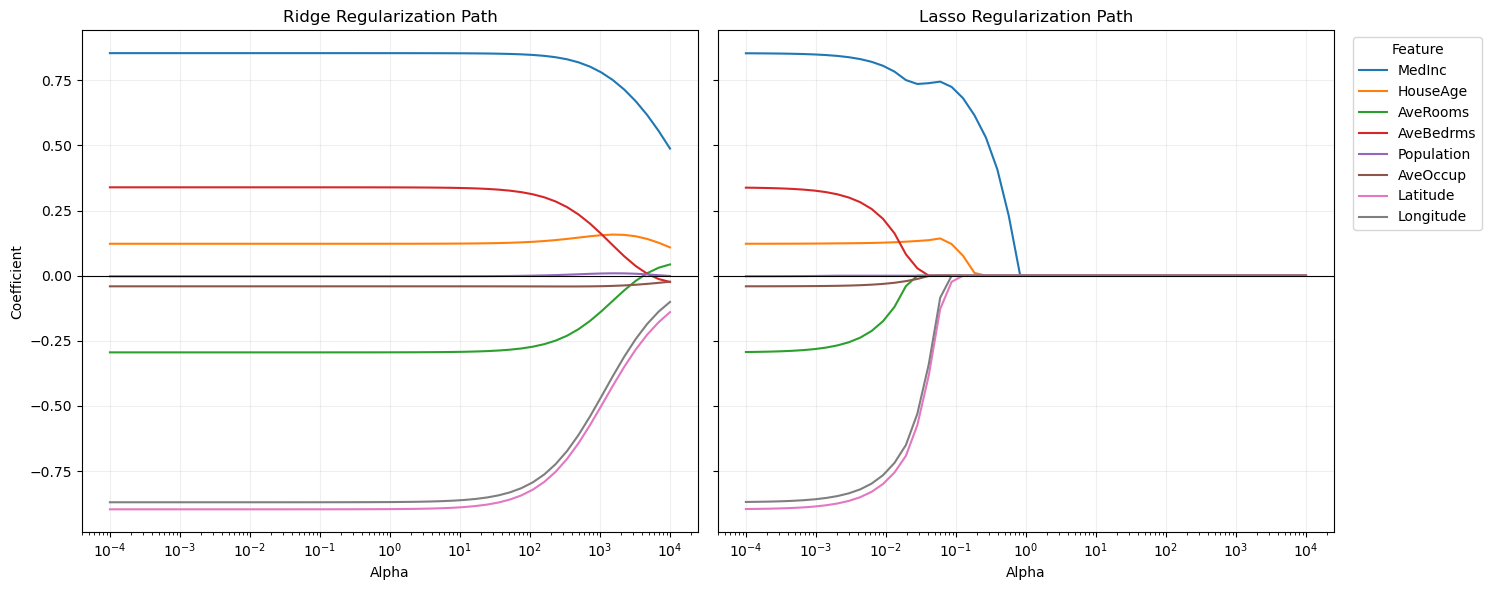

In [35]:
# Plot the Ridge and Lasso coefficient paths against alpha.
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for index, feature in enumerate(feature_names):
    axes[0].plot(alphas, ridge_path[:, index], label=feature)
    axes[1].plot(alphas, lasso_path[:, index], label=feature)
for ax, title in zip(axes, ["Ridge Regularization Path", "Lasso Regularization Path"]):
    ax.set_xscale("log")
    ax.set_xlabel("Alpha")
    ax.set_title(title)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Coefficient")
axes[1].legend(title="Feature", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()


## Logistic Regression Classification: Breast Cancer

Compare `lbfgs`, `liblinear`, and `saga` solvers on the Breast Cancer Wisconsin dataset.

In [ ]:
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)


In [ ]:
# Load the binary Breast Cancer dataset and create a stratified train/test split.
breast_cancer = load_breast_cancer(as_frame=True)
X_cls = breast_cancer.data
y_cls = breast_cancer.target
class_names = breast_cancer.target_names

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)


In [ ]:
# Standardize features using training-set statistics only.
scaler_cls = StandardScaler()
X_train_cls_scaled = scaler_cls.fit_transform(X_train_cls)
X_test_cls_scaled = scaler_cls.transform(X_test_cls)
print(f"Training samples: {len(X_train_cls)}")
print(f"Test samples: {len(X_test_cls)}")
print(f"Classes: {list(class_names)}")


In [ ]:
# Train one logistic regression model for each requested solver.
solvers = ["lbfgs", "liblinear", "saga"]
models_cls = {}
probabilities = {}

for solver in solvers:
    model = LogisticRegression(solver=solver, max_iter=10000, random_state=42)
    model.fit(X_train_cls_scaled, y_train_cls)
    models_cls[solver] = model
    probabilities[solver] = model.predict_proba(X_test_cls_scaled)[:, 1]


In [ ]:
# Print precision, recall, and F1-score for each class and solver.
for solver, model in models_cls.items():
    y_pred = model.predict(X_test_cls_scaled)
    print(f"\n=== Solver: {solver} ===")
    print(classification_report(
        y_test_cls, y_pred, target_names=class_names, digits=4, zero_division=0
    ))


### ROC curves and AUC

In [ ]:
# Plot ROC curves and calculate area under each ROC curve.
plt.figure(figsize=(8, 6))
roc_auc_scores = {}
for solver, y_score in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test_cls, y_score)
    roc_auc_scores[solver] = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{solver} (AUC = {roc_auc_scores[solver]:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("AUC by solver:", {k: round(v, 4) for k, v in roc_auc_scores.items()})


### Precision-Recall curves

In [ ]:
# Plot precision-recall curves for all solvers.
plt.figure(figsize=(8, 6))
for solver, y_score in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test_cls, y_score)
    plt.plot(recall, precision, label=solver)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Confusion matrices

In [ ]:
# Display one confusion matrix heatmap per solver in a 2x2 grid.
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.ravel()
for ax, solver in zip(axes, solvers):
    y_pred = models_cls[solver].predict(X_test_cls_scaled)
    cm = confusion_matrix(y_test_cls, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=class_names, yticklabels=class_names, ax=ax
    )
    ax.set_title(f"{solver} Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

# Hide the unused fourth panel because only three solvers are compared.
axes[3].axis("off")
fig.tight_layout()
plt.show()


### Decision threshold analysis

In [ ]:
# Calculate precision, recall, and F1 over thresholds from 0.1 through 0.9.
thresholds = np.linspace(0.1, 0.9, 81)
threshold_results = {}
for solver, y_score in probabilities.items():
    rows = []
    for threshold in thresholds:
        y_threshold_pred = (y_score >= threshold).astype(int)
        rows.append({
            "threshold": threshold,
            "precision": precision_score(y_test_cls, y_threshold_pred, zero_division=0),
            "recall": recall_score(y_test_cls, y_threshold_pred, zero_division=0),
            "f1": f1_score(y_test_cls, y_threshold_pred, zero_division=0),
        })
    threshold_results[solver] = pd.DataFrame(rows)


In [ ]:
# Plot threshold versus precision, recall, and F1 for each solver.
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, solver in zip(axes, solvers):
    result = threshold_results[solver]
    ax.plot(result["threshold"], result["precision"], label="Precision")
    ax.plot(result["threshold"], result["recall"], label="Recall")
    ax.plot(result["threshold"], result["f1"], label="F1-score")
    ax.set_title(solver)
    ax.set_xlabel("Decision threshold")
    ax.set_xlim(0.1, 0.9)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Score")
axes[-1].legend(loc="best")
fig.suptitle("Precision, Recall, and F1 Across Decision Thresholds")
fig.tight_layout()
plt.show()


In [ ]:
# Select and report each solver's threshold with the highest F1-score.
optimal_thresholds = {}
for solver, result in threshold_results.items():
    best_row = result.loc[result["f1"].idxmax()]
    optimal_thresholds[solver] = best_row["threshold"]
    print(
        f"{solver}: threshold={best_row['threshold']:.2f}, "
        f"precision={best_row['precision']:.4f}, "
        f"recall={best_row['recall']:.4f}, F1={best_row['f1']:.4f}"
    )
